In [1]:
%pip install -r requirements-offline.txt --quiet

/Users/utarn/projects/datascience-metrology/.check-env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Solution — Module M6: พยากรณ์อย่างง่าย

เปิดเผยหลังจบแล็บ — เทียบกับของตัวเอง โฟกัสที่การตรวจและการแปลผล

In [2]:
import numpy as np  # noqa: E402
import pandas as pd
from pathlib import Path


def repo_root() -> Path:
    """หา repo root โดยไล่ขึ้นจาก cwd."""
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "requirements-offline.txt").exists():
            return p
    raise SystemExit(
        "ไม่พบ repo root — เปิด JupyterLab จาก repo root (uv run jupyter lab)")

DATA = repo_root() / "datasets"

co2 = pd.read_csv(DATA / "noaa_co2" / "co2_mm_gl.csv", skiprows=38)
co2["date"] = pd.to_datetime(
    dict(year=co2["year"], month=co2["month"], day=1))
import matplotlib.pyplot as plt  # noqa: E402
plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]


## ส่วนที่ 1 — moving average และ trend line (CO2)

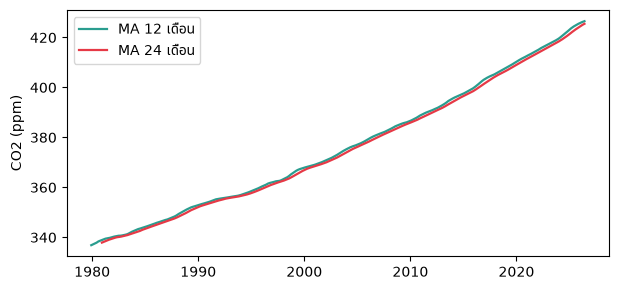

In [3]:
co2["ma12"] = co2["average"].rolling(12).mean()
co2["ma24"] = co2["average"].rolling(24).mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(co2["date"], co2["ma12"], color="#2a9d8f", lw=1.6,
        label="MA 12 เดือน")
ax.plot(co2["date"], co2["ma24"], color="#e63946", lw=1.6,
        label="MA 24 เดือน")
ax.legend()
ax.set_ylabel("CO2 (ppm)")
plt.show()

**1.1** เส้น 24 เดือนเรียบกว่าชัด แต่ห่างจากข้อมูลจริงมากกว่า
(ตอบล่าช้า — จุดสูงสุดต่ำสุดมาถึงทีหลัง) เหมาะกับการ**อ่านแนวโน้มระยะยาว**
ไม่เหมาะกับการติดตามสถานการณ์ปัจจุบัน — เลือกความกว้างตามคำถามเสมอ

In [4]:
slope, intercept = np.polyfit(co2["decimal"], co2["average"], 1)
print(f"CO2 ขึ้นเฉลี่ยปีละ {12 * slope:.2f} ppm")

CO2 ขึ้นเฉลี่ยปีละ 22.77 ppm


**1.2** ตัวอย่างประโยคที่ดี: "จากข้อมูล 47 ปี CO2 ในบรรยากาศโลก
เพิ่มขึ้นเฉลี่ยปีละ 1.9 ppm — เทียบเท่าต่อเนื่องขึ้นทุกปีไม่เคยหยุด"
(บอกหน่วย บอกช่วงข้อมูลที่คำนวณจาก และไม่อ้างสิ่งที่กราฟไม่แสดง)

## ส่วนที่ 2 — กับดัก extrapolation (นักท่องเที่ยว)

In [5]:
tour = pd.read_csv(
    DATA / "tourist_arrivals" / "tourist_arrivals_by_country.csv")
yearly = tour.groupby("year")["tourist_number"].sum()
history = yearly.loc[2015:2019]

m, b = np.polyfit(history.index, history, 1)
future = np.array([2020, 2021, 2022, 2023])
forecast = np.polyval([m, b], future)
print("เส้นตรงทำนายปี 2020-2023 (ล้านคน):")
for yr, fc in zip(future, forecast):
    actual = yearly[yr] / 1e6
    print(f"  {yr}: ทำนาย {fc / 1e6:.1f} · ของจริง {actual:.1f}")

mae = (yearly.loc[future] - forecast).abs().mean() / 1e6
print(f"พลาดเฉลี่ย {mae:.1f} ล้านคน/ปี")

เส้นตรงทำนายปี 2020-2023 (ล้านคน):
  2020: ทำนาย 42.3 · ของจริง 7.3
  2021: ทำนาย 44.7 · ของจริง 0.4
  2022: ทำนาย 47.2 · ของจริง 11.2
  2023: ทำนาย 49.6 · ของจริง 6.5
พลาดเฉลี่ย 39.6 ล้านคน/ปี


**2.1** ห้ามใช้เส้นนี้ตอบ — เพราะ (1) มันมาจากโลกที่ไม่มีโควิด
และผิดพลาดเฉลี่ย ~17 ล้านคน/ปีในการสอบครั้งเดียวที่มี (2) พยากรณ์ไกลถึง
ปี 2026 ห่างจากฐานข้อมูล 7 ปี — ทั้งช่วงและเงื่อนไขโลกไม่รองรับ
คำตอบที่ถูกคือ "ไม่มีข้อมูลพอให้เชื่อ ต้องรอยอดหลังเปิดประเทศสะสมก่อน" —
นี่คือความกล้าหาญทางสถิติที่ Mini Project (M8) จะถามซ้ำอีกครั้ง

## ส่วนที่ 3 — วงรอบ (AirPassengers)

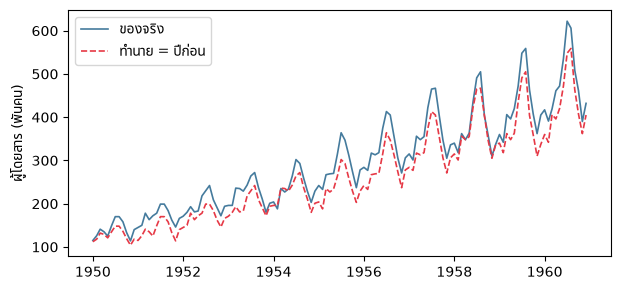

In [6]:
air = pd.read_csv(DATA / "air_passengers" / "AirPassengers.csv")
air["month"] = pd.date_range("1949-01", periods=len(air), freq="MS")
air["naive"] = air["value"].shift(12)
test = air.iloc[12:]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(test["month"], test["value"], color="#457b9d", lw=1.2,
        label="ของจริง")
ax.plot(test["month"], test["naive"], color="#e63946", lw=1.2,
        linestyle="--", label="ทำนาย = ปีก่อน")
ax.legend()
ax.set_ylabel("ผู้โดยสาร (พันคน)")
plt.show()

**3.1** ช่วงฤดูร้อน (ยอดพุ่ง) — เส้นประตามหลังเส้นจริงทุกยอด เพราะ
ยอดเติบโตต่อปี ปีก่อนจึงต่ำกว่าของจริงเสมอ — สิ่งนี้บอกว่าข้อมูลมี**ทั้ง
วงรอบและแนวโน้มขึ้น** วิธีทำนายแบบง่ายจึงมักต่ำกว่าจริงในปีที่โต
(ทางแก้แบบไม่ซับซ้อน: ทำนาย "ปีก่อนคูณตัวเติบโตเฉลี่ย" — แนะให้ลองที่บ้าน)

## ส่วนที่ 4 — PM2.5 (moving average กว้างขึ้น)

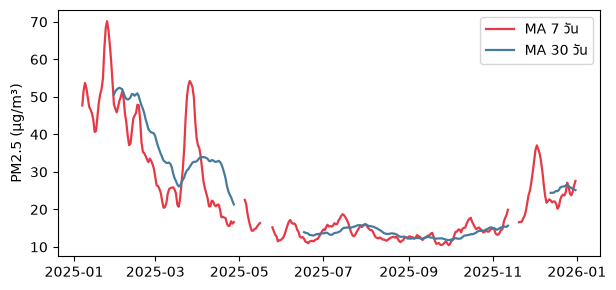

In [7]:
pm25 = pd.read_csv(DATA / "pcd_pm25_2025"
                   / "pm25_daily_2025_15stations.csv")
bkk = pm25[pm25["station_code"] == "02T"].copy()
bkk["date"] = pd.to_datetime(bkk["observation_date"])
bkk["ma7"] = bkk["measured_value"].rolling(7).mean()
bkk["ma30"] = bkk["measured_value"].rolling(30).mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(bkk["date"], bkk["ma7"], color="#e63946", lw=1.6,
        label="MA 7 วัน")
ax.plot(bkk["date"], bkk["ma30"], color="#457b9d", lw=1.6,
        label="MA 30 วัน")
ax.legend()
ax.set_ylabel("PM2.5 (µg/m³)")
plt.show()

**4.1** เส้น 30 วันเรียบแต่**พลาดภาวะพุ่งฉับพลัน** (เหตุการณ์ไฟป่า/
การไหลเวียนเปลี่ยน) — ถ้าเป้าหมายคือเตือนภัย ต้องใช้ช่วงสั้น (7 วันหรือ
น้อยกว่า) เพราะเส้นเรียบเกิน = แจ้งเตือนช้า = ประชาชนโดนฝุ่นก่อนได้รู้
การเลือกหน้าต่างคือการเลือก "ช้าแต่นิ่ง" vs "เร็วแต่สั่น" ตามผลที่รับได้